# Supervisor e Hierarquias

Um **supervisor** é um agente que recebe o pedido, decide a cada passo qual especialista trabalha e usa o resultado para escolher o passo seguinte. Esse **controle centralizado** produz uma **delegação dinâmica**, enquanto em um workflow fixo a ordem dos passos está no código. Equipes de agentes constroem aqui uma To-Do List e um agregador de notícias em Streamlit, com um supervisor e depois com uma **hierarquia**.

In [1]:
# No Google Colab, descomente e rode uma vez.

# !pip install -q langchain langchain-openai langgraph streamlit

# import os
# from google.colab import userdata

# os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")

In [2]:
import json
import re
import shutil
import subprocess
import sys
import tempfile
from collections import Counter
from pathlib import Path
from typing import Literal
from urllib.parse import urlencode
from urllib.request import urlopen

import pandas as pd
from IPython.display import Image
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from langchain.messages import HumanMessage
from langchain.tools import tool
from langgraph.graph import START, END, MessagesState, StateGraph
from langgraph.types import Command
from pydantic import BaseModel

In [3]:
model = init_chat_model(
    "openai:gpt-5.4-mini",
    reasoning_effort="low",
    use_responses_api=True,
    output_version="v0",
    timeout=120,
)

supervisor_model = init_chat_model(
    "openai:gpt-5.4-mini",
    reasoning_effort="low",
    use_responses_api=True,
    output_version="v0",
    timeout=120,
    model_kwargs={"parallel_tool_calls": False},
)

In [4]:
def user_message(text):
    """Monta a entrada do agente com uma mensagem do usuário."""
    return {"messages": [{"role": "user", "content": text}]}

Os agentes escrevem arquivos de verdade em uma pasta de trabalho, com as ferramentas abaixo, que usam só o nome do arquivo para não sair da pasta. As aplicações geradas abrem com `streamlit run` dentro dessa pasta, em um terminal.

In [5]:
WORKDIR = Path("workspace")
WORKDIR.mkdir(exist_ok=True)


@tool
def write_file(path: str, content: str) -> str:
    """Escreve um arquivo na pasta de trabalho, substituindo o conteúdo anterior."""
    (WORKDIR / Path(path).name).write_text(content)
    return f"{path} salvo com {len(content.splitlines())} linhas."


@tool
def read_file(path: str) -> str:
    """Lê um arquivo da pasta de trabalho."""
    file = WORKDIR / Path(path).name
    return file.read_text() if file.is_file() else f"{path} não existe."

## Supervisor

No LangGraph, o supervisor é um nó que lê a conversa e devolve um `Command(goto=...)` com o próximo nó, e cada especialista é um nó que volta ao supervisor. Todos leem o mesmo histórico, e a resposta de cada especialista entra nele como uma mensagem com o nome dele. A equipe tem um desenvolvedor backend, que escreve a lógica em Python, e um desenvolvedor frontend, que escreve a interface em Streamlit.

In [ ]:
BACKEND_PROMPT = """# Papel
Você é um desenvolvedor backend Python.

# Regras
Escreva só a lógica, em funções Python, e salve os arquivos com write_file.
Nunca escreva arquivos de interface, mesmo que o pedido cite um: a interface fica com o frontend.
Para alterar um arquivo existente, leia-o antes com read_file.
Responda em até cinco linhas com os arquivos salvos, a assinatura de cada função pública e as chaves dos dicionários que ela devolve."""

In [ ]:
FRONTEND_PROMPT = """# Papel
Você é um desenvolvedor frontend que escreve interfaces em Streamlit.

# Regras
A interface chama as funções do backend e não reimplementa a lógica. Use st.rerun, e não st.experimental_rerun.
Salve os arquivos com write_file. Para alterar um arquivo existente, leia-o antes com read_file.
Responda em até três linhas com os arquivos salvos e o que mudou neles."""

In [ ]:
backend_agent = create_agent(model, tools=[write_file, read_file], system_prompt=BACKEND_PROMPT)
frontend_agent = create_agent(model, tools=[write_file, read_file], system_prompt=FRONTEND_PROMPT)

In [7]:
class Route(BaseModel):
    next: Literal["backend", "frontend", "FINISH"]


SUPERVISOR_PROMPT = """# Papel
Você coordena uma equipe de desenvolvimento e não escreve código.

# Equipe
- backend escreve a lógica em Python;
- frontend escreve a interface em Streamlit, que usa as funções do backend.

# Regras
Leia a conversa e escolha quem trabalha a seguir.
Responda FINISH assim que as mensagens da equipe atenderem o pedido do usuário."""

In [8]:
def supervisor_node(state: MessagesState) -> Command[Literal["backend", "frontend", "__end__"]]:
    """Escolhe o próximo membro da equipe ou encerra."""
    messages = [{"role": "system", "content": SUPERVISOR_PROMPT}] + state["messages"]
    route = model.with_structured_output(Route).invoke(messages)
    print("supervisor:", route.next)
    if route.next == "FINISH":
        return Command(goto=END)
    return Command(goto=route.next)

In [9]:
def backend_node(state: MessagesState) -> Command[Literal["supervisor"]]:
    """Roda o backend sobre a conversa e devolve a resposta ao supervisor."""
    result = backend_agent.invoke(state)
    message = HumanMessage(content=result["messages"][-1].text, name="backend")
    return Command(goto="supervisor", update={"messages": [message]})


def frontend_node(state: MessagesState) -> Command[Literal["supervisor"]]:
    """Roda o frontend sobre a conversa e devolve a resposta ao supervisor."""
    result = frontend_agent.invoke(state)
    message = HumanMessage(content=result["messages"][-1].text, name="frontend")
    return Command(goto="supervisor", update={"messages": [message]})

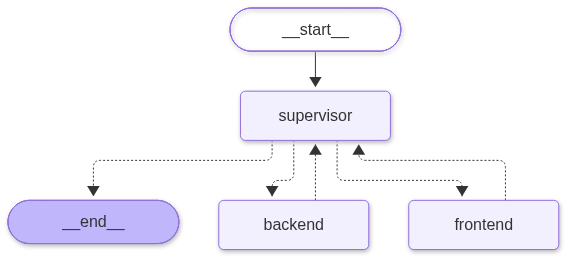

In [10]:
builder = StateGraph(MessagesState)
builder.add_node("supervisor", supervisor_node)
builder.add_node("backend", backend_node)
builder.add_node("frontend", frontend_node)
builder.add_edge(START, "supervisor")

graph = builder.compile()
Image(graph.get_graph().draw_mermaid_png())

In [11]:
TEST_REQUEST = "Teste a To-Do List, com a lógica em todo.py e a interface em todo_app.py, e corrija o que falhar."

TODO_REQUEST = "Crie uma To-Do List em Streamlit, com cadastro, listagem, conclusão e remoção de tarefas, guardadas em tasks.json. A lógica fica em todo.py e a interface em todo_app.py."

TITLE_REQUEST = "Na interface da To-Do List, em todo_app.py, troque o título da página para Minhas Tarefas."

In [12]:
%%time
graph_result = graph.invoke(user_message(TODO_REQUEST))

supervisor: backend


supervisor: frontend


supervisor: FINISH
CPU times: user 395 ms, sys: 40.7 ms, total: 436 ms
Wall time: 19.3 s


In [13]:
for message in graph_result["messages"]:
    message.pretty_print()

================================ Human Message =================================

Crie uma To-Do List em Streamlit, com cadastro, listagem, conclusão e remoção de tarefas, guardadas em tasks.json. A lógica fica em todo.py e a interface em todo_app.py.
================================ Human Message =================================
Name: backend

Salvei `todo.py` com a lógica de tarefas em `tasks.json` (não criei `todo_app.py` por regra de não escrever interface).  
Funções públicas: `load_tasks(path=TASKS_FILE)`, `save_tasks(tasks, path=TASKS_FILE)`, `list_tasks(path=TASKS_FILE)`, `add_task(title, path=TASKS_FILE)`, `complete_task(task_id, path=TASKS_FILE)`, `remove_task(task_id, path=TASKS_FILE)`.  
Dicionários retornados: `list_tasks` → `tasks`, `total`, `done`; `add_task` → `task`, `tasks`, `total`; `complete_task` → `task`, `tasks`, `total`; `remove_task` → `tasks`, `total`, `removed_id`.
================================ Human Message =================================
Name: fronten

In [14]:
%%time
title_result = graph.invoke(user_message(TITLE_REQUEST))

supervisor: frontend


supervisor: FINISH
CPU times: user 95.8 ms, sys: 12.3 ms, total: 108 ms
Wall time: 9.67 s


O supervisor chamou o backend, depois o frontend, e encerrou com FINISH. O backend viu no histórico compartilhado o pedido da interface e deixou `todo_app.py` para o frontend, por causa da regra do prompt, e o frontend usou as funções que o backend listou na resposta. No pedido do título, o supervisor chamou só o frontend.

### Exercício 1

Acrescente ao grafo um nó documentador, que escreve um README.md com o que a aplicação faz e como executá-la. Atualize `Route`, o prompt do supervisor e o grafo, e peça a documentação da To-Do List. Por quais nós o pedido passou?

In [ ]:
# Seu código aqui

## Subagentes como ferramentas

A mesma equipe pode ser montada com `create_agent`: cada especialista vira um **subagente**, chamado como ferramenta pelo supervisor. O subagente roda em uma conversa nova e vê só a tarefa que o supervisor escreveu, então o frontend só conhece as funções do backend se a tarefa disser quais são. O `supervisor_model` desliga as chamadas paralelas, para que o supervisor delegue uma tarefa de cada vez.

In [16]:
@tool
def backend(task: str) -> str:
    """Entrega ao desenvolvedor backend uma tarefa sobre a lógica em Python."""
    result = backend_agent.invoke(user_message(task))
    return result["messages"][-1].text


@tool
def frontend(task: str) -> str:
    """Entrega ao desenvolvedor frontend uma tarefa sobre a interface em Streamlit."""
    result = frontend_agent.invoke(user_message(task))
    return result["messages"][-1].text

In [17]:
DEV_PROMPT = """# Papel
Você supervisiona uma equipe de desenvolvimento e não escreve código.

# Regras
Cada tarefa traz tudo de que o membro precisa, porque ele não vê esta conversa:
os nomes dos arquivos e, para o frontend, o arquivo, as funções e as chaves dos dados que o backend entregou.
Responda em até cinco linhas com os arquivos entregues."""

dev_agent = create_agent(
    supervisor_model,
    tools=[backend, frontend],
    system_prompt=DEV_PROMPT,
)

In [18]:
%%time
dev_result = dev_agent.invoke(user_message(TODO_REQUEST))

CPU times: user 197 ms, sys: 29.4 ms, total: 227 ms
Wall time: 25.7 s


In [19]:
for message in dev_result["messages"]:
    message.pretty_print()

================================ Human Message =================================

Crie uma To-Do List em Streamlit, com cadastro, listagem, conclusão e remoção de tarefas, guardadas em tasks.json. A lógica fica em todo.py e a interface em todo_app.py.
================================== Ai Message ==================================

[]
Tool Calls:
  backend (call_5biPozUOgehWpgx97xaMjJcG)
 Call ID: call_5biPozUOgehWpgx97xaMjJcG
  Args:
    task: Implemente a lógica da To-Do List no arquivo todo.py. Requisitos: persistir tarefas em tasks.json; suportar cadastro, listagem, marcação de conclusão e remoção; usar uma estrutura simples por tarefa com campos id, titulo, concluida, criada_em. Exponha funções claras para o frontend usar, por exemplo: carregar_tarefas(), salvar_tarefas(), adicionar_tarefa(titulo), concluir_tarefa(task_id), remover_tarefa(task_id). Garanta que o arquivo tasks.json seja criado se não existir e que as operações sejam robustas contra arquivo vazio ou inválido.
======

O supervisor escreveu cada tarefa por conta própria. Na do backend, ele sugeriu nomes de funções em português, que o backend adotou; na do frontend, copiou as funções que o backend devolveu, porque o frontend só vê essa tarefa. No grafo, todos os nós leem o mesmo histórico, e com ferramentas cada subagente recebe só a tarefa que o supervisor escreveu.

### Exercício 2

Transforme o documentador do Exercício 1 em uma ferramenta e monte um supervisor com `DEV_PROMPT` e as ferramentas `backend`, `frontend` e a nova. Peça a ele a documentação da To-Do List. Quais ferramentas o supervisor chamou, e o que a tarefa do documentador dizia sobre os arquivos?

In [ ]:
# Seu código aqui

## Delegação iterativa

Um testador escreve testes e os roda com `run_tests`, em uma cópia da pasta de trabalho que protege os dados. Quando um teste falha, o supervisor decide quem corrige e testa de novo, até aprovar ou atingir o limite de rodadas da ferramenta `test`, que também acrescenta à tarefa os casos de aceitação do cliente, em `ACCEPTANCE`. O `recursion_limit` limita os passos do grafo do agente.

In [21]:
@tool
def run_tests(code: str) -> str:
    """Executa um programa Python em uma cópia da pasta de trabalho e devolve o que ele imprimiu e os erros."""
    with tempfile.TemporaryDirectory() as folder:
        shutil.copytree(WORKDIR, folder, dirs_exist_ok=True)
        process = subprocess.run([sys.executable, "-c", code], cwd=folder, capture_output=True, text=True, timeout=60)
    return process.stdout[-3000:] + process.stderr[-3000:]

In [ ]:
ACCEPTANCE = """- concluir ou remover uma tarefa que não existe levanta KeyError;
- concluir uma tarefa já concluída levanta ValueError;
- uma tarefa nova nunca recebe o ID de uma tarefa já criada, mesmo depois de remoções."""

In [ ]:
TESTER_PROMPT = """# Papel
Você é um testador.

# Regras
Leia o código com read_file e escreva os testes como um programa Python simples, sem pytest,
que importa os arquivos e imprime o resultado de cada teste. Rode-o com run_tests.
Comece cada teste sem o arquivo de dados, a menos que o teste use os dados prontos.
Teste uma interface Streamlit com AppTest.from_file(arquivo).run(), de streamlit.testing.v1: ela falha se app.exception não estiver vazio.
Teste o código exatamente como está, sem corrigi-lo nem reescrevê-lo.
Rode também os casos de aceitação que valerem para o código testado.
Responda APROVADO só se todos passaram. Um único teste falho dá REPROVADO, com cada falha, em até dez linhas."""

In [ ]:
tester_agent = create_agent(model, tools=[read_file, run_tests], system_prompt=TESTER_PROMPT)

In [23]:
test_rounds = []


@tool
def test(task: str) -> str:
    """Entrega ao testador o código a testar, com os nomes dos arquivos."""
    if len(test_rounds) == 5:
        return "Limite de cinco rodadas de teste atingido. Encerre com o resultado atual."
    result = tester_agent.invoke(user_message(f"{task}\n\n# Casos de aceitação da To-Do List\n{ACCEPTANCE}"))
    test_rounds.append(result["messages"][-1].text)
    return test_rounds[-1]

In [ ]:
DEV_LEAD_PROMPT = """# Papel
Você supervisiona uma equipe de desenvolvimento e não escreve código.

# Regras
1. A aplicação tem lógica e interface. O backend trabalha antes do frontend, que recebe o arquivo,
as funções e as chaves dos dados do backend.
2. Envie ao test os dois arquivos, sem escrever casos de teste.
3. Se o teste reprovar, envie cada falha a quem escreveu o arquivo e teste de novo.
4. Sua resposta final vai para quem fez o pedido, e não para a equipe. Responda só quando o teste
aprovar ou o limite for atingido, em até cinco linhas, com os arquivos e o resultado dos testes."""

In [ ]:
dev_lead_agent = create_agent(
    supervisor_model,
    tools=[backend, frontend, test],
    system_prompt=DEV_LEAD_PROMPT,
).with_config(recursion_limit=60)

In [25]:
def delegations(result):
    """Mostra as ferramentas que um supervisor chamou, com o começo de cada tarefa."""
    calls = [call for message in result["messages"] if message.type == "ai" for call in message.tool_calls]
    return pd.DataFrame([{"ferramenta": call["name"], "tarefa": " ".join(map(str, call["args"].values()))[:120]} for call in calls])

In [26]:
%%time
test_rounds.clear()
lead_result = dev_lead_agent.invoke(user_message(TEST_REQUEST))

CPU times: user 706 ms, sys: 115 ms, total: 821 ms
Wall time: 1min 15s


In [27]:
delegations(lead_result)

,ferramenta,tarefa
0,backend,Implementar a lógica da To-Do List em `todo.py...
1,frontend,Criar a interface em `todo_app.py` com Streaml...
2,test,Testar os arquivos `todo.py` e `todo_app.py`. ...
3,backend,Corrigir `todo.py` conforme falhas do teste: 1...
4,test,Retestar os arquivos `todo.py` e `todo_app.py`...


In [28]:
for round_text in test_rounds:
    print(round_text, end="\n\n")

REPROVADO

- `todo.py`: `complete_task(..., id_inexistente)` não levanta `KeyError`; retorna `{"error": "task_not_found"}`.
- `todo.py`: `remove_task(..., id_inexistente)` não levanta `KeyError`; retorna `{"error": "task_not_found"}`.
- `todo.py`: concluir tarefa já concluída não levanta `ValueError`; a função aceita a operação e devolve sucesso.
- A interface `todo_app.py` funcionou nos fluxos básicos testados com Streamlit (`AppTest`), incluindo adicionar, editar, concluir, remover e erro de texto vazio.

APROVADO



Na primeira rodada, os casos de aceitação falharam: concluir ou remover uma tarefa inexistente devolvia um dicionário de erro em vez de levantar `KeyError`. O supervisor repassou as falhas ao backend, e a rodada seguinte aprovou. As tarefas do supervisor não citam os casos de aceitação, que a ferramenta `test` acrescentou, e o número de rodadas saiu dos resultados dos testes.

### Exercício 3

Crie um subagente revisor, que lê o código e aponta só os erros que o fariam falhar, e um supervisor com as ferramentas de `dev_lead_agent` e o revisor, cujo prompt acrescenta ao `DEV_LEAD_PROMPT` uma revisão antes de cada teste. Esvazie `test_rounds` e peça a mesma tarefa. Em que ordem as ferramentas foram chamadas?

In [ ]:
# Seu código aqui

## Hierarquias

Em uma **hierarquia**, um subagente é ele próprio um supervisor com subagentes. Um supervisor geral vai coordenar a equipe de desenvolvimento, que é o `dev_lead_agent`, e uma equipe de dados, com um buscador e um analista de notícias. A busca usa a API pública do Hacker News e guarda as notícias em `news_raw.json`, devolvendo ao modelo só os títulos. A ferramenta `data_team` recebe só um tema.

In [ ]:
@tool
def search_news(query: str) -> str:
    """Busca as notícias mais recentes no Hacker News e acrescenta as dez primeiras a news_raw.json."""
    url = "https://hn.algolia.com/api/v1/search_by_date?" + urlencode({"query": query, "tags": "story", "hitsPerPage": 10})
    hits = json.loads(urlopen(url, timeout=30).read())["hits"]
    file = WORKDIR / "news_raw.json"
    news = json.loads(file.read_text()) if file.exists() else []
    news += [{"title": hit["title"], "date": hit["created_at"], "points": hit["points"], "link": hit.get("url") or f"https://news.ycombinator.com/item?id={hit['objectID']}"} for hit in hits]
    file.write_text(json.dumps(news, ensure_ascii=False, indent=2))
    return "\n".join(hit["title"] for hit in hits) or "Nenhuma notícia encontrada com esses termos."

In [ ]:
@tool
def save_analysis(path: str, topics: list[str], summaries: dict[str, str]) -> str:
    """Salva em path as notícias de news_raw.json. Em topics vai o assunto de cada notícia,
    na ordem do arquivo, e em summaries o resumo de cada assunto."""
    news = json.loads((WORKDIR / "news_raw.json").read_text())
    if not news:
        return "news_raw.json está vazio: não há notícias para salvar."
    if len(topics) != len(news):
        return f"São {len(news)} notícias e {len(topics)} assuntos. Envie um assunto por notícia."
    for item, topic in zip(news, topics):
        item["topic"] = topic
    counts = Counter(topics)
    data = {"news": news, "topics": [{"topic": t, "count": counts[t], "summary": summaries.get(t, "")} for t in counts]}
    (WORKDIR / Path(path).name).write_text(json.dumps(data, ensure_ascii=False, indent=2))
    return f"{path} salvo com as chaves news (title, date, points, link, topic) e topics (topic, count, summary)."

O formato do arquivo de análise fica no código de `save_analysis`, e não no prompt do analista, e a resposta da ferramenta diz as chaves que as outras equipes vão usar.

In [ ]:
SEARCHER_PROMPT = """# Papel
Você busca notícias.

# Regras
Faça de uma a três buscas para cada tema pedido. Cada busca tem uma ou duas palavras-chave em inglês, como AI ou solar power,
sem palavras como news ou recent, porque a busca exige todas as palavras no título.
Responda em até três linhas com quantas notícias encontrou."""

In [ ]:
ANALYST_PROMPT = """# Papel
Você analisa notícias.

# Regras
Leia news_raw.json com read_file e escolha você, lendo os títulos, um assunto específico para cada notícia,
como regulação ou chips. Use de quatro a oito assuntos, nenhum com mais da metade das notícias.
Salve com save_analysis no arquivo indicado na tarefa, com um resumo em português do que as notícias de cada assunto dizem.
Responda com o arquivo e as chaves que save_analysis informou."""

In [ ]:
searcher_agent = create_agent(model, tools=[search_news], system_prompt=SEARCHER_PROMPT)
analyst_agent = create_agent(model, tools=[read_file, save_analysis], system_prompt=ANALYST_PROMPT)

In [ ]:
@tool
def searcher(task: str) -> str:
    """Entrega ao buscador os temas das notícias que ele deve buscar."""
    return searcher_agent.invoke(user_message(task))["messages"][-1].text


@tool
def analyst(task: str) -> str:
    """Entrega ao analista as notícias encontradas para classificar e resumir por assunto."""
    return analyst_agent.invoke(user_message(task))["messages"][-1].text

In [ ]:
DATA_PROMPT = """# Papel
Você supervisiona uma equipe de dados e não executa tarefas.

# Regras
1. Peça ao searcher as notícias do tema.
2. Peça ao analyst que classifique as notícias e salve a análise no arquivo do pedido.
3. Responda com o arquivo e as chaves que o analista informou."""

data_lead_agent = create_agent(supervisor_model, tools=[searcher, analyst], system_prompt=DATA_PROMPT).with_config(recursion_limit=60)

In [ ]:
team_results = {"data_team": [], "dev_team": []}


@tool
def data_team(theme: str) -> str:
    """Entrega à equipe de dados um tema curto, como energia solar. Ela busca e analisa as notícias e devolve o arquivo gerado e suas chaves."""
    (WORKDIR / "news_raw.json").unlink(missing_ok=True)
    file = "news_" + "_".join(re.findall(r"\w+", theme.lower())) + ".json"
    result = data_lead_agent.invoke(user_message(f"Busque e analise notícias sobre {theme}. Salve a análise em {file}."))
    team_results["data_team"].append(result)
    return result["messages"][-1].text

In [ ]:
@tool
def dev_team(task: str) -> str:
    """Entrega à equipe de desenvolvimento uma aplicação para construir e testar."""
    team_results["dev_team"].append(dev_lead_agent.invoke(user_message(task)))
    return team_results["dev_team"][-1]["messages"][-1].text

In [ ]:
GENERAL_PROMPT = """# Papel
Você é o supervisor geral e coordena duas equipes, sem executar tarefas.

# Equipes
- data_team recebe um tema, busca notícias reais e devolve um arquivo JSON com a análise;
- dev_team constrói aplicações em Python e Streamlit, com testes, e não tem acesso à internet.

# Regras
Uma aplicação que mostra notícias usa as que a data_team buscou, então a data_team trabalha antes.
A dev_team não vê esta conversa nem o trabalho da data_team: copie literalmente
na tarefa dela os arquivos e as chaves do JSON que a data_team devolveu.
Responda em até cinco linhas com os arquivos entregues."""

In [ ]:
general_agent = create_agent(
    supervisor_model,
    tools=[data_team, dev_team],
    system_prompt=GENERAL_PROMPT,
).with_config(recursion_limit=60)

In [36]:
NEWS_REQUEST = "Crie em Streamlit um agregador de notícias sobre inteligência artificial, com resumos, links das fontes e gráficos dos principais assuntos."

In [37]:
%%time
test_rounds.clear()
general_result = general_agent.invoke(user_message(NEWS_REQUEST))

CPU times: user 680 ms, sys: 82.5 ms, total: 762 ms
Wall time: 1min 27s


In [38]:
for message in general_result["messages"]:
    message.pretty_print()

================================ Human Message =================================

Crie em Streamlit um agregador de notícias sobre inteligência artificial, com resumos, links das fontes e gráficos dos principais assuntos.
================================== Ai Message ==================================

[]
Tool Calls:
  data_team (call_8vAOHiR7rIjn0AWffB9jeXDT)
 Call ID: call_8vAOHiR7rIjn0AWffB9jeXDT
  Args:
    theme: inteligência artificial
================================= Tool Message =================================
Name: data_team

Arquivo gerado: **news_inteligência_artificial.json**

Chaves/campos do JSON:
- **news**: `title`, `date`, `points`, `link`, `topic`
- **topics**: `topic`, `count`, `summary`
================================== Ai Message ==================================

[]
Tool Calls:
  dev_team (call_aNkfHp1WXbsNveMtRwlNx53O)
 Call ID: call_aNkfHp1WXbsNveMtRwlNx53O
  Args:
    task: Crie uma aplicação em Streamlit em Python para um agregador de notícias sobre intel

In [39]:
delegations(team_results["data_team"][-1])

,ferramenta,tarefa
0,searcher,Buscar notícias recentes sobre inteligência ar...
1,analyst,Classifique e resuma as notícias sobre intelig...


In [40]:
delegations(team_results["dev_team"][-1])

,ferramenta,tarefa
0,backend,Crie o arquivo de backend em Python para a apl...
1,frontend,Crie o arquivo de frontend em Streamlit para a...
2,test,Teste os arquivos `news_backend.py` e `app_str...


O supervisor geral chamou a `data_team` com o tema e, com o arquivo e as chaves que ela devolveu, escreveu a tarefa da `dev_team`. Cada equipe repetiu dentro dela o padrão do supervisor: a de dados chamou o searcher e o analyst, e a de desenvolvimento chamou backend, frontend e test. O supervisor geral recebeu só as respostas finais das equipes.

### Exercício 4

Peça ao `general_agent` um agregador que compare as notícias sobre inteligência artificial com as notícias sobre energia solar. Em que ordem o supervisor geral chamou as equipes, e o que ele repassou de uma equipe para a outra?

In [ ]:
# Seu código aqui